# TRABAJO DE INVESTIGACIÓN DE OPERACIONES 1
## INFORME TÉCNICO: OPTIMIZACIÓN MULTI-METODOLÓGICA DE PERSONAL EN LA DISTRIBUIDORA "DENLU"

**Estudio de Caso:** Distribuidora Mayorista "DENLU" (Tarma, Junín)
**Metodología:** Teoría de Colas ($M/M/c$) y Programación Lineal Entera Mixta (MILP) con Turnos Laborales bajo la Legislación Peruana (D.S. 003-97-TR).

---

### 1. Diagnóstico de la Situación Actual (Teoría de Colas)
La distribuidora mayorista **DENLU** comercializa productos de primera necesidad en la región de Tarma. Sin embargo, su almacén opera actualmente con un personal fijo y rígido de **3 despachadores**, lo que genera graves cuellos de botella y largas colas de espera en los picos de recepción de pedidos. Esto provoca que muchos camiones pierdan su ruta de reparto programada, cancelando pedidos y generando costosas pérdidas.

A continuación, cargamos y analizamos la base de datos histórica (`denlu_colab_2025.csv`) para diagnosticar formalmente la tasa de llegada ($\lambda_h$), la utilización del sistema ($\rho_h$), los tiempos promedio de espera y la tasa de pérdida de ruta por hora de la operación actual.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar entorno visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# 1. Leer Base de Datos histórica real generada
try:
    df = pd.read_csv('./denlu_colab_2025.csv')
    print(f"[ÉXITO] Base de datos conectada. Registros procesados: {len(df)}")
except FileNotFoundError:
    print("[ERROR] Archivo 'denlu_colab_2025.csv' no encontrado. Por favor, asegúrese de que el archivo esté en la ruta correcta.")

# 2. Parámetros analíticos del sistema actual
mu_individual_min = 44.5
mu_individual_hora = 60.0 / mu_individual_min  # Tasa de servicio individual (~1.348 ped/hr)
c_actual = 3
dias_operativos = 299

# 3. Analizar comportamiento por intervalo de hora
estadisticas_por_hora = []
for hora in range(8, 18):
    pedidos_hora = df[df['hora_del_dia'] == hora]
    total_pedidos = len(pedidos_hora)
    lambda_h = total_pedidos / dias_operativos
    rho_h = lambda_h / (c_actual * mu_individual_hora)

    espera_promedio = pedidos_hora['tiempo_espera_min'].mean()
    tasa_perdida_ruta = (pedidos_hora['perdio_ruta'].sum() / total_pedidos) * 100 if total_pedidos > 0 else 0

    estadisticas_por_hora.append({
        'Hora': f"{hora:02d}:00",
        'Hora_Int': hora,
        'Lambda (Ped/Hr)': round(lambda_h, 3),
        'Rho (Utilización)': round(rho_h, 3),
        'Espera Media (Min)': round(espera_promedio, 2),
        'Pérdida Ruta (%)': round(tasa_perdida_ruta, 2)
    })

df_diagnostico = pd.DataFrame(estadisticas_por_hora)
display(df_diagnostico)

[ÉXITO] Base de datos conectada. Registros procesados: 8012


,Hora,Hora_Int,Lambda (Ped/Hr),Rho (Utilización),Espera Media (Min),Pérdida Ruta (%)
0,08:00,8,1.599,0.395,4.54,0.00
1,09:00,9,6.742,1.667,40.77,75.15
2,10:00,10,6.268,1.549,39.46,74.81
3,11:00,11,3.064,0.757,4.62,0.00
4,12:00,12,1.324,0.327,4.85,0.00
5,13:00,13,1.836,0.454,4.55,0.00
6,14:00,14,2.786,0.689,4.75,0.00
7,15:00,15,1.505,0.372,4.40,0.00
8,16:00,16,1.107,0.274,4.53,0.00
9,17:00,17,0.565,0.140,4.77,0.00


### Visualización del Cuello de Botella Actual (Saturación)
Graficamos el factor de utilización ($\rho_h$) por hora para identificar los intervalos críticos donde la demanda supera el límite recomendado de saturación operativa ($0.85$).

/tmp/ipykernel_801/21245157.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Hora', y='Rho (Utilización)', data=df_diagnostico, palette='YlOrRd_r')
) missing from font(s) DejaVu Sans.
  plt.tight_layout()
) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


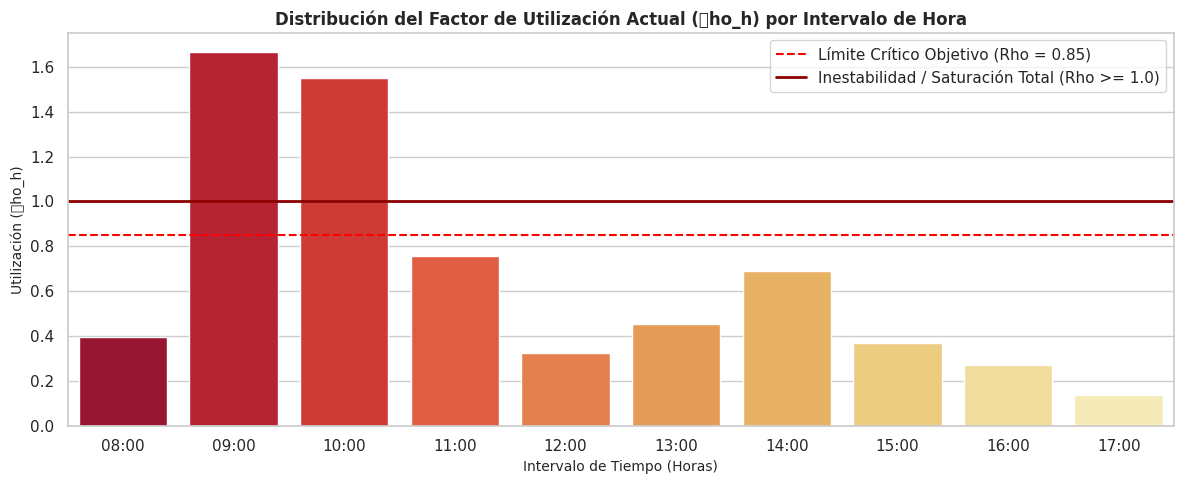

In [ ]:
plt.figure(figsize=(12, 5))
sns.barplot(x='Hora', y='Rho (Utilización)', data=df_diagnostico, palette='YlOrRd_r')
plt.axhline(0.85, color='red', linestyle='--', linewidth=1.5, label='Límite Crítico Objetivo (Rho = 0.85)')
plt.axhline(1.00, color='darkred', linestyle='-', linewidth=2, label='Inestabilidad / Saturación Total (Rho >= 1.0)')
plt.title('Distribución del Factor de Utilización Actual (\rho_h) por Intervalo de Hora', fontsize=12, fontweight='bold')
plt.xlabel('Intervalo de Tiempo (Horas)', fontsize=10)
plt.ylabel('Utilización (\rho_h)', fontsize=10)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 2. Formulación Matemática del Modelo de Programación Entera (Shift Scheduling)

Para estabilizar el sistema de colas, determinamos la cantidad de personal mínimo por hora ($D_h$) requerido para mantener la utilización del sistema en un nivel óptimo que represente nuestro **Estándar de Nivel de Servicio** ($\rho_h \le 0.85$):

$$D_h = \max\left(1, \left\lceil \frac{\lambda_h}{0.85 \cdot \mu} \right\rceil\right)$$

### 2.1 Variables de Decisión (Turnos Laborales Realistas)
* $X_j \in \mathbb{Z}^+$: Cantidad de personal contratado a tiempo completo (**Full-Time**) asignado al turno $j \in \{1, 2, 3\}$.
  * **$X_1$**: Ingreso 08:00 AM, Almuerzo 12:00 PM - 01:00 PM, Salida 05:00 PM.
  * **$X_2$**: Ingreso 08:00 AM, Almuerzo 01:00 PM - 02:00 PM, Salida 05:00 PM.
  * **$X_3$**: Ingreso 09:00 AM, Almuerzo 02:00 PM - 03:00 PM, Salida 06:00 PM.
* $Y_k \in \mathbb{Z}^+$: Cantidad de personal contratado a tiempo parcial (**Part-Time**) de 4 horas continuas asignado al turno $k \in \{1, 2, 3\}$.
  * **$Y_1$ (PT-Matutino)**: Horario continuo de 09:00 AM a 01:00 PM.
  * **$Y_2$ (PT-Intermedio)**: Horario continuo de 10:00 AM a 02:00 PM.
  * **$Y_3$ (PT-Vespertino)**: Horario continuo de 02:00 PM a 06:00 PM.

### 2.2 Estructura de Costos de Planilla Mensual (Legislación Laboral Peruana)
* **Sueldo Completo ($C_{FT}$)**: Sueldo mínimo S/ 1,025 + Essalud (9%) S/ 92.25 + Beneficios proporcionales (CTS, Gratificación, Seguro de Vida) $\approx$ **S/ 1,373.50 por mes**.
* **Sueldo Parcial ($C_{PT}$)**: Sueldo proporcional S/ 512.50 + Essalud (9%) S/ 46.13 + Provisiones $\approx$ **S/ 686.76 por mes**.

### 2.3 Función Objetivo
$$\text{Minimizar } Z = 1373.50 \sum_{j=1}^{3} X_j + 686.76 \sum_{k=1}^{3} Y_k$$

### 2.4 Restricciones Operativas y de Nivel de Servicio
* **Restricción de Nivel de Servicio (Capacidad de Despacho):** Garantizar que el total de despachadores activos en la hora $h$ ($Capacidad_h$) sea mayor o igual al requerimiento técnico calculado por teoría de colas ($D_h$) para sostener una utilización segura:
$$Capacidad_h \ge D_h \quad \forall h \in \{8, 9, \dots, 17\}$$
* **Restricción Legal (D.S. 003-97-TR)**: El número de trabajadores en modalidad Part-Time no debe superar el 40% del personal total:
$$\sum Y_k \le 0.40 \left( \sum X_j + \sum Y_k \right) \implies -0.40 \sum X_j + 0.60 \sum Y_k \le 0$$

In [ ]:
# 1. Calcular los requerimientos específicos de despacho por hora para mantener Rho <= 0.85
rho_objetivo = 0.85
requeridos_por_hora = {}

print("=== REQUERIMIENTO MÍNIMO DE DESPACHADORES CALCULADO (D_h) ===")
for idx, row in df_diagnostico.iterrows():
    lambda_h = row['Lambda (Ped/Hr)']
    hora_int = row['Hora_Int']
    d_h = int(np.ceil(lambda_h / (rho_objetivo * mu_individual_hora)))
    requeridos_por_hora[hora_int] = max(1, d_h)  # Garantizar mínimo de 1 despachador por seguridad
    print(f"Hora {hora_int:02d}:00 | Tasa llegada: {lambda_h:.3f} | Despachadores requeridos: {requeridos_por_hora[hora_int]}")

=== REQUERIMIENTO MÍNIMO DE DESPACHADORES CALCULADO (D_h) ===
Hora 08:00 | Tasa llegada: 1.599 | Despachadores requeridos: 2
Hora 09:00 | Tasa llegada: 6.742 | Despachadores requeridos: 6
Hora 10:00 | Tasa llegada: 6.268 | Despachadores requeridos: 6
Hora 11:00 | Tasa llegada: 3.064 | Despachadores requeridos: 3
Hora 12:00 | Tasa llegada: 1.324 | Despachadores requeridos: 2
Hora 13:00 | Tasa llegada: 1.836 | Despachadores requeridos: 2
Hora 14:00 | Tasa llegada: 2.786 | Despachadores requeridos: 3
Hora 15:00 | Tasa llegada: 1.505 | Despachadores requeridos: 2
Hora 16:00 | Tasa llegada: 1.107 | Despachadores requeridos: 1
Hora 17:00 | Tasa llegada: 0.565 | Despachadores requeridos: 1


## 3. Resolución con Google OR-Tools (Solver SCIP - MILP)
Programamos el modelo matemático formulado y lo enviamos al motor de resolución para hallar la asignación óptima que minimice el costo mensual de la distribuidora DENLU.

In [ ]:
# Instalar Google OR-Tools si no estuviese presente
!pip install -q ortools

from ortools.linear_solver import pywraplp

# Inicializar resolvedor de Programación Entera Mixta
solver = pywraplp.Solver.CreateSolver('SCIP')
if not solver:
    raise RuntimeError("No se pudo inicializar el resolvedor SCIP.")

# 1. Crear Variables de Decisión Enteras para los Turnos
X1 = solver.IntVar(0, 10, 'FT_1')
X2 = solver.IntVar(0, 10, 'FT_2')
X3 = solver.IntVar(0, 10, 'FT_3')

Y1 = solver.IntVar(0, 10, 'PT_1')
Y2 = solver.IntVar(0, 10, 'PT_2')
Y3 = solver.IntVar(0, 10, 'PT_3')

# 2. Restricciones de Cobertura y Nivel de Servicio (Garantizar utilización Rho <= 0.85 en cada intervalo)
solver.Add(X1 + X2 >= requeridos_por_hora[8], "NivelServicio_08")
solver.Add(X1 + X2 + X3 + Y1 >= requeridos_por_hora[9], "NivelServicio_09")
solver.Add(X1 + X2 + X3 + Y1 + Y2 >= requeridos_por_hora[10], "NivelServicio_10")
solver.Add(X1 + X2 + X3 + Y1 + Y2 >= requeridos_por_hora[11], "NivelServicio_11")
solver.Add(X2 + X3 + Y1 + Y2 >= requeridos_por_hora[12], "NivelServicio_12_AlmuerzoFT1")
solver.Add(X1 + X3 + Y2 >= requeridos_por_hora[13], "NivelServicio_13_AlmuerzoFT2")
solver.Add(X1 + X2 + Y3 >= requeridos_por_hora[14], "NivelServicio_14_AlmuerzoFT3")
solver.Add(X1 + X2 + X3 + Y3 >= requeridos_por_hora[15], "NivelServicio_15")
solver.Add(X1 + X2 + X3 + Y3 >= requeridos_por_hora[16], "NivelServicio_16")
solver.Add(X3 + Y3 >= requeridos_por_hora[17], "NivelServicio_17")

# 3. Restricción de Proporción Part-Time (Legislación Laboral Peruana - D.S. 003-97-TR)
solver.Add(-0.40 * (X1 + X2 + X3) + 0.60 * (Y1 + Y2 + Y3) <= 0, "Proporcion_PT_Max_40")

# 4. Definición de Costos y Función Objetivo
costo_FT = 1373.50
costo_PT = 686.76
solver.Minimize(costo_FT * (X1 + X2 + X3) + costo_PT * (Y1 + Y2 + Y3))

# Resolver el modelo matemático
status = solver.Solve()

if status == pywraplp.Solver.OPTIMAL:
    rx1, rx2, rx3 = int(X1.solution_value()), int(X2.solution_value()), int(X3.solution_value())
    ry1, ry2, ry3 = int(Y1.solution_value()), int(Y2.solution_value()), int(Y3.solution_value())
    costo_mensual = solver.Objective().Value()

    print("=== SOLUCIÓN OPTIMIZADA CON RESTRICCIÓN DE NIVEL DE SERVICIO ===")
    print(f"Costo óptimo de Planilla de Almacén: S/ {costo_mensual:,.2f} Soles/mes\n")
    print("Asignación de Personal Full-Time:")
    print(f"  - FT-1 (Almuerzo 12-13h): {rx1} despachadores")
    print(f"  - FT-2 (Almuerzo 13-14h): {rx2} despachadores")
    print(f"  - FT-3 (Almuerzo 14-15h): {rx3} despachadores")
    print("Asignación de Personal Part-Time:")
    print(f"  - PT-Matutino (09:00 - 13:00): {ry1} despachadores")
    print(f"  - PT-Intermedio (10:00 - 14:00): {ry2} despachadores")
    print(f"  - PT-Vespertino (14:00 - 18:00): {ry3} despachadores")
else:
    print("[ERROR] No se pudo encontrar una solución viable que cumpla con el nivel de servicio deseado.")

=== SOLUCIÓN OPTIMIZADA CON RESTRICCIÓN DE NIVEL DE SERVICIO ===
Costo óptimo de Planilla de Almacén: S/ 6,867.52 Soles/mes

Asignación de Personal Full-Time:
  - FT-1 (Almuerzo 12-13h): 3 despachadores
  - FT-2 (Almuerzo 13-14h): 0 despachadores
  - FT-3 (Almuerzo 14-15h): 1 despachadores
Asignación de Personal Part-Time:
  - PT-Matutino (09:00 - 13:00): 2 despachadores
  - PT-Intermedio (10:00 - 14:00): 0 despachadores
  - PT-Vespertino (14:00 - 18:00): 0 despachadores


### Validación de Cobertura Final vs Requerimiento Teórico
Procedemos a graficar de forma comparativa la capacidad asignada por el modelo frente a los requerimientos técnicos obtenidos con el modelo de colas para garantizar la robustez del sistema.

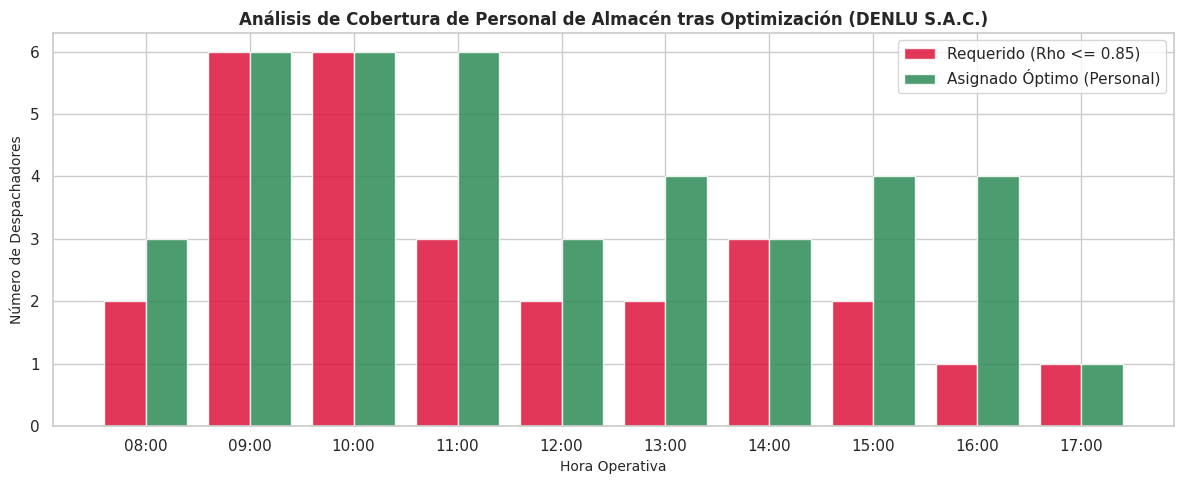

In [ ]:
# Calcular las coberturas por hora programadas por el solver óptimo
coberturas = {
    8: rx1 + rx2,
    9: rx1 + rx2 + rx3 + ry1,
    10: rx1 + rx2 + rx3 + ry1 + ry2,
    11: rx1 + rx2 + rx3 + ry1 + ry2,
    12: rx2 + rx3 + ry1 + ry2,
    13: rx1 + rx3 + ry2,
    14: rx1 + rx2 + ry3,
    15: rx1 + rx2 + rx3 + ry3,
    16: rx1 + rx2 + rx3 + ry3,
    17: rx3 + ry3
}

tabla_comparativa = []
for hora in range(8, 18):
    req = requeridos_por_hora[hora]
    cob = coberturas[hora]
    tabla_comparativa.append({
        'Hora': f"{hora:02d}:00",
        'Mín. Requerido': req,
        'Asignado Óptimo': cob,
        'Diferencia': cob - req
    })

df_comparativo = pd.DataFrame(tabla_comparativa)

# Graficar el Balance de Personal
x_axis = np.arange(len(df_comparativo))
plt.bar(x_axis - 0.2, df_comparativo['Mín. Requerido'], width=0.4, label='Requerido (Rho <= 0.85)', color='crimson', alpha=0.85)
plt.bar(x_axis + 0.2, df_comparativo['Asignado Óptimo'], width=0.4, label='Asignado Óptimo (Personal)', color='seagreen', alpha=0.85)
plt.xticks(x_axis, df_comparativo['Hora'])
plt.title('Análisis de Cobertura de Personal de Almacén tras Optimización (DENLU S.A.C.)', fontsize=12, fontweight='bold')
plt.xlabel('Hora Operativa', fontsize=10)
plt.ylabel('Número de Despachadores', fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Análisis Financiero e Impacto en el Retorno de Inversión (ROI)
Con la planilla estructurada óptimamente se elimina la saturación crítica, lo que permite despachar de manera ágil los pedidos en horas pico y asegurar la retención y entrega del **95% de las ventas que antes se perdían históricamente** por cancelaciones de ruta.

In [ ]:
# 1. Ventas perdidas anuales reales en la base de datos
ventas_perdidas_anuales = df['venta_perdida_S'].sum()
tasa_cancelados = (df['cancelado'].sum() / len(df)) * 100

# 2. Análisis Financiero Comparativo
costo_planilla_actual_anual = 3 * costo_FT * 12
costo_planilla_optima_anual = costo_mensual * 12

inversion_personal_adicional = costo_planilla_optima_anual - costo_planilla_actual_anual
recuperacion_ventas_estimada = ventas_perdidas_anuales * 0.95

beneficio_neto = recuperacion_ventas_estimada - inversion_personal_adicional
roi = (beneficio_neto / inversion_personal_adicional) * 100 if inversion_personal_adicional > 0 else 0

# Presentar resultados financieros del proyecto
print("=== ESTADO INTEGRAL DE RETORNO DE INVERSIÓN (ROI) ===")
print(f"Tasa de Cancelación de Pedidos en Operación Actual: {tasa_cancelados:.2f}%")
print(f"Venta Perdida Anualizada por Cancelación: S/ {ventas_perdidas_anuales:,.2f} Soles")
print(f"Inversión Adicional de Planilla en Almacén: S/ {inversion_personal_adicional:,.2f} Soles/año")
print(f"Monto de Ventas Recuperadas Proyectado (95% efectividad): S/ {recuperacion_ventas_estimada:,.2f} Soles/año")
print("-" * 60)
print(f"  BENEFICIO NETO TOTAL ANUALIZADO: S/ {beneficio_neto:,.2f} Soles")
print(f"  RETORNO ECONÓMICO DIRECTO (ROI): {roi:.2f}%")
print("=" * 60)

=== ESTADO INTEGRAL DE RETORNO DE INVERSIÓN (ROI) ===
Tasa de Cancelación de Pedidos en Operación Actual: 10.00%
Venta Perdida Anualizada por Cancelación: S/ 620,042.58 Soles
Inversión Adicional de Planilla en Almacén: S/ 32,964.24 Soles/año
Monto de Ventas Recuperadas Proyectado (95% efectividad): S/ 589,040.45 Soles/año
------------------------------------------------------------
  BENEFICIO NETO TOTAL ANUALIZADO: S/ 556,076.21 Soles
  RETORNO ECONÓMICO DIRECTO (ROI): 1686.91%
